# Lab #2: Probability, Distributions, and Statistical Questions

In [71]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
from scipy.stats import norm
from scipy.stats import expon
from scipy.stats import poisson
from scipy import signal
import math

## Problem 1

In lecture and homework we explored how the convolution can be used to
calculate the probability of a sum or average. For this problem we are
going to imagine that we are looking for gamma-ray sources (e.g. with
the [Fermi telescope](https://fermi.gsfc.nasa.gov)). In this kind of
telescope there is a background of cosmic-rays (electrons and protons,
mostly) that provides a discrete noise term across the sky that
precisely follows a Poisson distribution. To detect a gamma-ray source,
you need to ask what is the probability that the cosmic-ray background
would have given you a measurement as signal-like or more than the
signal that you received.

To set up the problem, assume in 1 day the average cosmic-ray background
is some number X (pick someting btwn 0.5 and 10, with different values
for you and your lab partner); and the average number of gamma-rays
emitted by your hypothetical source is Y (pick something larger than X).

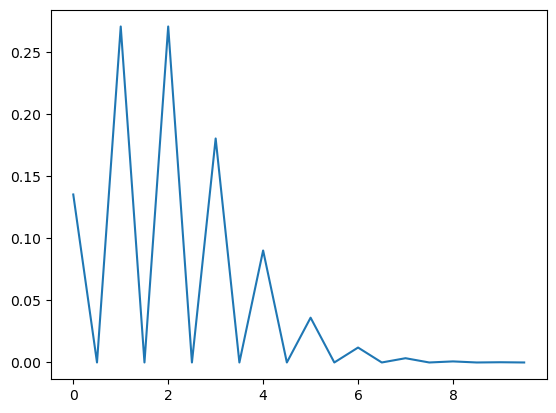

In [66]:
# creating a numpy array for x-axis
x = np.arange(0, 10, 0.5)

# poisson distribution data for y-axis
y = poisson.pmf(x, mu=2)


# plotting the graph
plt.plot(x, y)

# showing the graph
plt.show()

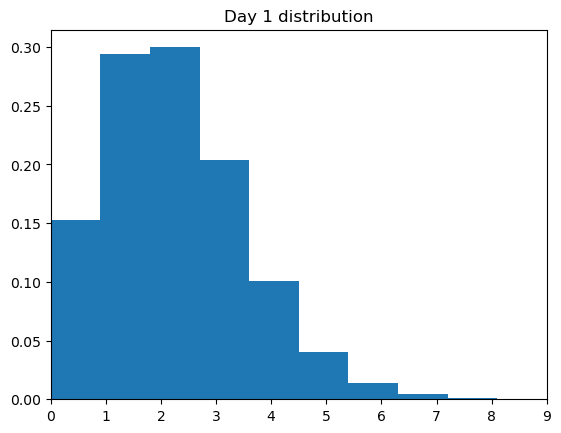

In [52]:
# Distributions of background cosmic rays for 1 day
dis_d1 = np.random.poisson(2, 10000)

#plots
count, bins, ignored = plt.hist(dis_d1, density=True)
plt.xlim([0,9])
x = np.linspace(0,9,100)
plt.title("Day 1 distribution")
plt.show()

A) Show how the probability distribution of the background changes as
you integrate (sum) for more days.

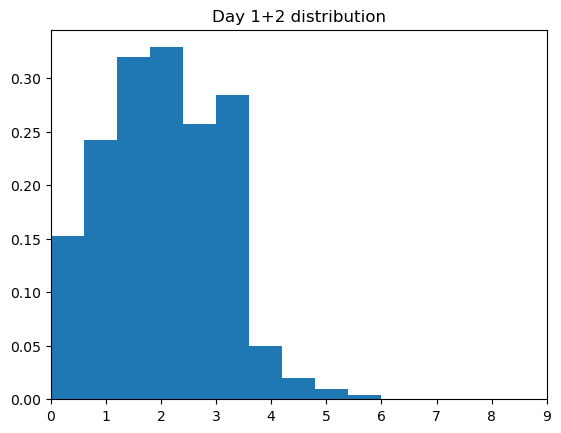

In [59]:
# Distributions of background cosmic rays for 2 days
dis_d2 = (dis_d1 + np.random.poisson(2, 10000)) / 2

#plots
count, bins, ignored = plt.hist(dis_d2, density=True)
plt.xlim([0,9])
x = np.linspace(0,9,100)
plt.title("Day 1+2 distribution")
plt.show()

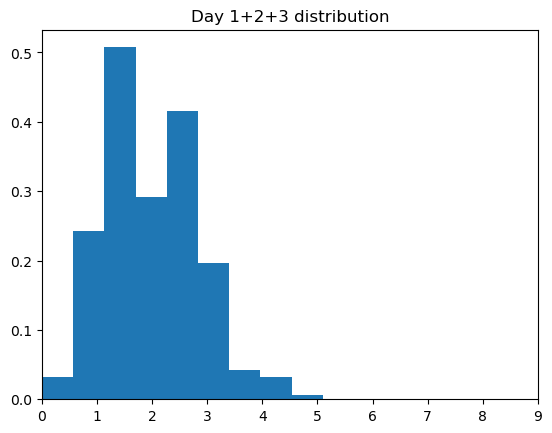

In [60]:
# Distributions of background cosmic rays for 3 days
dis_d3 = (2* dis_d2 + np.random.poisson(2, 10000)) / 3

#plots
count, bins, ignored = plt.hist(dis_d3, density=True)
plt.xlim([0,9])
x = np.linspace(0,9,100)
plt.title("Day 1+2+3 distribution")
plt.show()

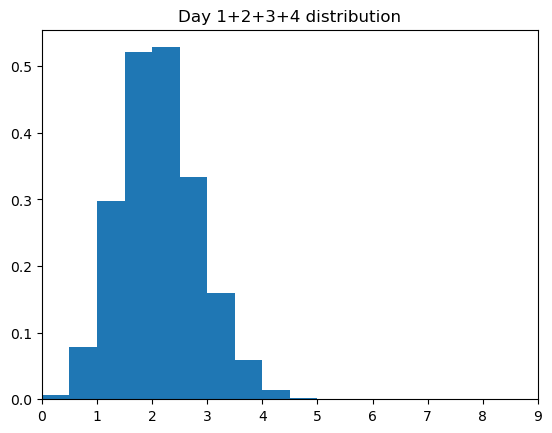

In [61]:
# Distributions of background cosmic rays for 4 days
dis_d4 = (3*dis_d3 + np.random.poisson(2, 10000))/ 4

#plots
count, bins, ignored = plt.hist(dis_d4, density=True)
plt.xlim([0,9])
x = np.linspace(0,9,100)
plt.title("Day 1+2+3+4 distribution")
plt.show()

B) Show that after 5 days, the summed probability distribution is still
a Poisson distribution. Explain why this makes sense from a mathematical
and conceptual point of view.

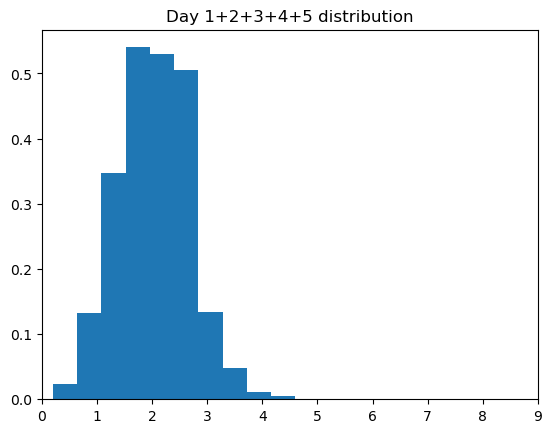

In [65]:
# Distributions of background cosmic rays for 5 days
dis_d5 = (4*dis_d4 + np.random.poisson(2, 10000)) / 5

#plots
count, bins, ignored = plt.hist(dis_d5, density=True)
plt.xlim([0,9])
x = np.linspace(0,9,100)
plt.title("Day 1+2+3+4+5 distribution")
plt.show()

The distribution still looks like a poisson due to the fact that we're not changing the underlying distribution when we add more days. What we're doing is taking more samples, which can perhaps reduce the variance of the distribution we approximate from the data itself, but don't change the core statistics of the true distribution they originate from. Mathematically, the random variable we care about is still the same (an rv from a poisson with mean 2), and therefore the distribution is already fixed.

C) Show how the probability distribution evolves as you *average* days.
Calculate for many different ranges of days, and explore the shape of
the distribution as the number of days becomes larger. Discuss this in
relation to both B) and the central limit theoem.

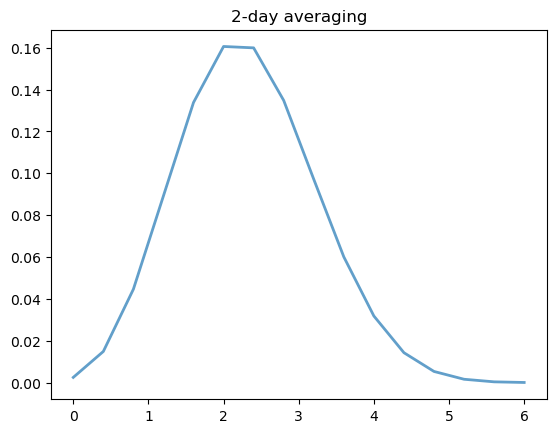

In [103]:
# Here one must convolve and rescale x-axis
# Start with 2 days
ran = 2
mu = 2

x = np.arange(poisson.ppf(0.01, mu),
              poisson.ppf(0.99, mu))

conv = scipy.stats.poisson.pmf(x, mu)

for i in range(ran):
    conv = scipy.signal.convolve(conv, scipy.stats.poisson.pmf(x,mu), mode='full')

#plots
fig, ax = plt.subplots(1,1)
ax.plot(np.linspace(poisson.ppf(0.01, mu),
              poisson.ppf(0.99, mu), len(conv)), conv, linewidth=2, alpha=0.7)
plt.title("2-day averaging")
plt.show()


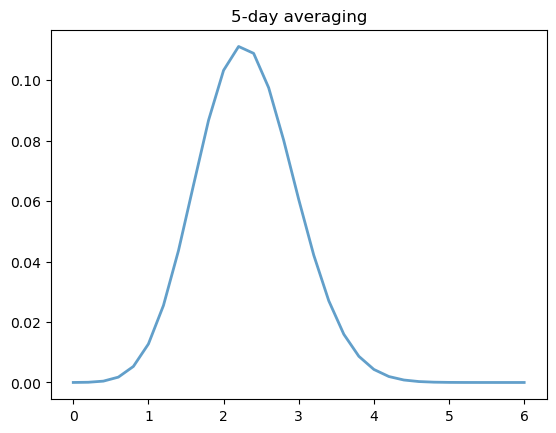

In [105]:
# Here one must convolve and rescale x-axis
# Start with 5 days
ran = 5
mu = 2

x = np.arange(poisson.ppf(0.01, mu),
              poisson.ppf(0.99, mu))

conv_5 = scipy.stats.poisson.pmf(x, mu)

for i in range(ran):
    conv_5 = scipy.signal.convolve(conv_5, scipy.stats.poisson.pmf(x,mu), mode='full')

#plots
fig, ax = plt.subplots(1,1)
x_5 = np.linspace(poisson.ppf(0.01, mu),
              poisson.ppf(0.99, mu), len(conv_5))
ax.plot(x_5, conv_5, linewidth=2, alpha=0.7)
plt.title("5-day averaging")
plt.show()


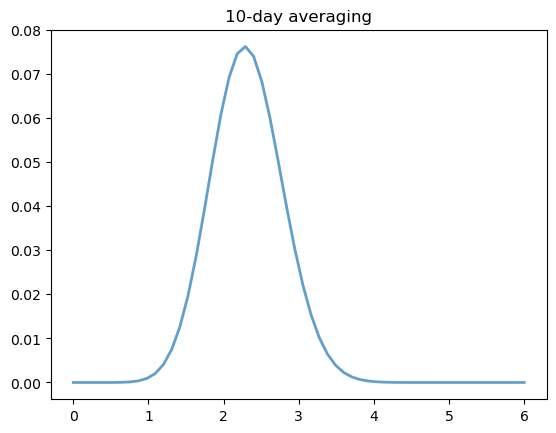

In [101]:
# Here one must convolve and rescale x-axis
# Start with 10 days
ran = 10
mu = 2

x = np.arange(poisson.ppf(0.01, mu),
              poisson.ppf(0.99, mu))

conv = scipy.stats.poisson.pmf(x, mu)

for i in range(ran):
    conv = scipy.signal.convolve(conv, scipy.stats.poisson.pmf(x,mu), mode='full')

#plots
fig, ax = plt.subplots(1,1)
ax.plot(np.linspace(poisson.ppf(0.01, mu),
              poisson.ppf(0.99, mu), len(conv)), conv, linewidth=2, alpha=0.7)
plt.title("10-day averaging")
plt.show()


The distribution starts converging to a Gaussian since the average of many independent random variables also converges to a normal distribution by the central limit theorem--if we averaged over an infinite number of days, then we would in fact have a normal distribtion as expected. This doesn't look like the Poisson distribution from B) since there, we morally only took more samples (and didn't actually change the distribution itself). Here, we are measuring an entirely new random variable, which this average of all the poisson random variables, whose distribution doesn't necessarily have to follow that of the original random variables.

D) Pick some number of days N, and assume you saw Y*N gamma rays from
your source. Calculate the 'sigma' of your observation. (In reality the
number of gamma-rays seen from a source will also fluctuate, but we're
going to ignore that complication for a couple of labs)

In [122]:
# We pick 5 days, and use the convolved distribution from there (Which tracks the sum of background rays)
Y = 5
x = np.arange(0, len(conv_5))
prob_YN = 0
for i in range(25, len(conv_5)):
    prob_YN += conv_5[i]
sigma = scipy.stats.norm.isf(prob_YN)
print(f"The sigma of observing Y*N events given the background distributions is: {round(sigma, 2)}")

The sigma of observing Y*N events given the background distributions is: 3.95


## Problem 2

Pick a skewed continuous distribtuion, such as a Rayleigh, that
describes your background over some observing interval.

A) Show how the distribution changes as you average over more observing
intervals.

In [ ]:

B) Discuss how the shape changes. Does it approach a Gaussian
distribution? If yes, after how many intervals?

## Problem 3

The discovery of optical/infra-red counterparts of Neutron star mergers
initially detected with gravity-waves is one of the great discoverys in
the last few years ([wikipedia](https://en.wikipedia.org/wiki/GW170817),
[scientific paper](https://arxiv.org/abs/1710.05833)), and has ushered
in the age of "multi-messenger astrophysics." The science that can be
done by matching a gravity-wave signal (directly measures the mass of
the neutron stars and their distance) with the optical emisson
(redshift, nuclear astrophysics of the resulting explosion) is
*staggering*. Lots of science from how the heaviest elements are formed
to constraints on Dark Energy.

We're going to explore one of the analysis questions that comes up when
looking for the optical counterparts (a new optical source) of a gravity
wave signal. For this problem let's assume that we are using an optical
telescope with a thermal noise background from the CCD (dark current,
particularly an issue with older CCDs and/or infra-red CCDs). After
flat-fielding, the background appears as a zero-mean Gaussian with
constant width over the image.

### Version 1

You have an alert from [LIGO](https://www.ligo.caltech.edu) that is also
seen in with the X-ray/ultra-violet satellite
[SWIFT](https://swift.gsfc.nasa.gov). SWIFT gives you a very precise
location, so you take an image of that part of the sky. But because of
SWIFT's accuracy, you know which pixel in your image to look for a
counterpart in.

A) From looking at all the other pixels in your image, you can measure
the width of the background Gaussian distribution X (pick something).
Assuming you see a signal of strength Y (pick a floating-point number;
typical optical CCDs are not sensitive enough to count photons so the
readings are floating point brightnesses, not integer photons).
Calculate the significance of your detection. Can you claim a discovery
(traditionally 5-sigma or more)?

### Version 2

You have an alert from LIGO, but no associated detection from SWIFT.
This could be because it is a black hole-black hole merger, a black
hole-neutron star merger (neither seem to emit X-rays or UV light), or
it could because SWIFT was indisposed at the time (wrong side of the
earth in its orbit). Whatever the cause, you know what region of the sky
to look in, but not which pixel.

B) If you have to look for a signal in 10k pixels, what is the
probability distribution of your background? (*Clearly* state the
statistical question, then turn that into math using your background
distribution from part 1 of this problem.)

C) Taking your brightest candidate signal from the region (assume it
has the same signal as in part 1), calculate the significance of your
detection.

## Problem 4

The statistical issue we were exploring in the previous problem is
called a **trials factor** (sometimes known as a look-elsewhere effect).
This is an important effect, as if you search through a million
locations, you would expect to see approximately 1 one-in-a-million
event. However, it is also often over estimated how big an impact this
makes on the sensitivity of a search. So in this part of the lab we are
going to invert the problem.

Let us again assume we have a Gaussian background (same parameters as
Problem 3).

A) Calculate the signal required for a 5-sigma detection in Version 1

B) Calculate the signal required for a 5-sigma detection in Version 2

C) Discuss how much brighter the signal must be for discoverey if you
have a trials factor of 10k. Looking at your probability distributions,
explain why the sensitivity penalty due to a trials factor is so low.

D) If you changed the trials factor significantly (orders of
magnitude), how large is the effect on your 5-sigma sensitivity
threshold?

Extra credit: If you had a different distribution shape (non-Gaussian),
how would that affect the sensitivity penalty of many trials? Clearly
explain.